# Threshold curve in the $(p, p_{\mathrm{bell},z})$ plane — `biased_bell_v2`

Headline figure: every fitted threshold is a 2D point $(p^*, p_{\mathrm{bell},z}^*)$
on the noise plane.

- **bias scan**: direction $\beta = p_{\mathrm{bell},z}/p$, threshold lands at
  $(p^*, \beta \cdot p^*)$.
- **fixed-$p_{\mathrm{bell},z}$ scan**: $p_{\mathrm{bell},z}$ held constant,
  threshold lands at $(p^*, p_{\mathrm{bell},z}^{\mathrm{fixed}})$.

Reads the per-direction fits saved by `threshold_comparison_bell.ipynb`
(`out/collection/threshold_bell_fits.csv`).

In [9]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
fits_path = Path('../out/collection/threshold_bell_fits.csv')
if not fits_path.exists():
    raise FileNotFoundError(
        f'No fits at {fits_path}. Run threshold_comparison_bell.ipynb first.'
    )

fits_df = pd.read_csv(fits_path)
fits_df

,direction,direction_kind,bias,p_bell_z_fixed,p_th,p_th_err,mu,mu_err,p_init,n_points
0,bias=0,bias,0.0,NaN,0.002423,0.000022,0.930004,0.046166,0.002512,15
1,bias=1,bias,1.0,NaN,0.002036,0.000018,0.841453,0.035499,0.001995,15
2,bias=3,bias,3.0,NaN,0.001488,0.000013,0.942626,0.037977,0.001585,14
3,bias=10,bias,10.0,NaN,0.000799,0.000007,0.866917,0.029981,0.000858,14
4,bias=30,bias,30.0,NaN,0.000349,0.000004,0.790182,0.025319,0.000341,13
5,bias=100,bias,100.0,NaN,0.000117,0.000002,0.931060,0.055457,0.000136,8
6,pbz=0.001,pbz,NaN,0.001,0.002216,0.000019,0.928855,0.045378,0.002154,15
7,pbz=0.01,pbz,NaN,0.010,0.000527,0.000017,1.035512,0.069778,0.000631,15


In [11]:
bias_df = (
    fits_df[fits_df['direction_kind'] == 'bias']
    .sort_values('bias')
    .reset_index(drop=True)
)
pbz_df = (
    fits_df[fits_df['direction_kind'] == 'pbz']
    .sort_values('p_bell_z_fixed')
    .reset_index(drop=True)
)
print(f'{len(bias_df)} bias points, {len(pbz_df)} fixed-pbz points')

6 bias points, 2 fixed-pbz points


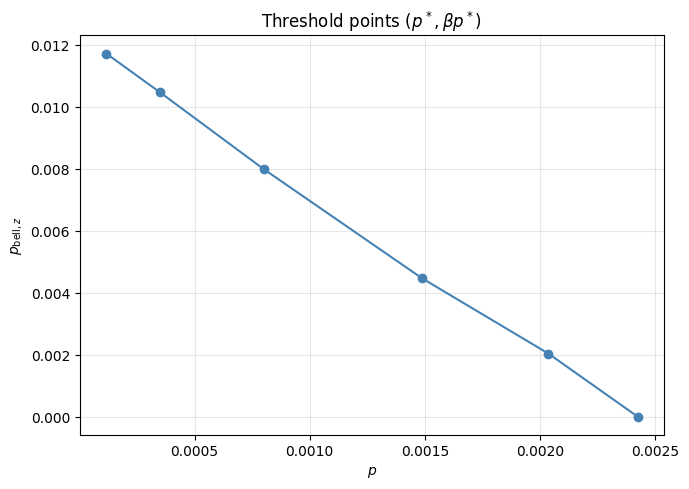

In [12]:
# Each fitted threshold -> point (p_th, beta * p_th) on the (p, p_bell_z) plane.
fig, ax = plt.subplots(figsize=(7, 5))

if len(bias_df):
    p = bias_df['p_th'].to_numpy(dtype=float)
    pbz = bias_df['bias'].to_numpy(dtype=float) * p
    ax.plot(p, pbz, 'o-', color='steelblue')

ax.set_xlabel(r'$p$')
ax.set_ylabel(r'$p_{\mathrm{bell},z}$')
ax.set_title(r'Threshold points $(p^*, \beta p^*)$')
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

In [ ]:
# p_th vs fixed p_bell_z (independent scan, easier to interpret
# experimentally because p_bell_z is set by hardware).
if len(pbz_df):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.errorbar(
        pbz_df['p_bell_z_fixed'], pbz_df['p_th'], yerr=pbz_df['p_th_err'],
        fmt='s-', color='darkorange',
        label=r'$p^*(p_{\mathrm{bell},z})$, fixed-pbz scan',
    )
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$p_{\mathrm{bell},z}$ (fixed)')
    ax.set_ylabel(r'Threshold $p^*$')
    ax.set_title(r'Threshold vs fixed $p_{\mathrm{bell},z}$ — biased_bell_v2')
    ax.grid(True, alpha=0.3, which='both')
    ax.legend()
    fig.tight_layout()
    plt.show()
else:
    print('No fixed-pbz fits to plot.')

In [ ]:
# Combined view: both scans on one (p_bell_z, p_th) plane.
# - bias scan: each point is (p_th * beta, p_th).
# - fixed-pbz scan: each point is (p_bell_z_fixed, p_th).
fig, ax = plt.subplots(figsize=(7, 5))

if len(bias_df):
    bx = bias_df['bias'] * bias_df['p_th']
    ax.errorbar(
        bx, bias_df['p_th'], yerr=bias_df['p_th_err'],
        fmt='o-', color='steelblue', label='bias scan',
    )
if len(pbz_df):
    ax.errorbar(
        pbz_df['p_bell_z_fixed'], pbz_df['p_th'], yerr=pbz_df['p_th_err'],
        fmt='s-', color='darkorange', label='fixed-pbz scan',
    )

ax.plot(
    [1e-6, 1.0], [1e-6, 1.0],
    color='gray', linestyle=':', alpha=0.5, label=r'$p^* = p_{\mathrm{bell},z}$',
)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$p_{\mathrm{bell},z}$ at threshold')
ax.set_ylabel(r'Threshold $p^*$')
ax.set_title(r'Threshold trajectories on the $(p_{\mathrm{bell},z}, p)$ plane')
ax.grid(True, alpha=0.3, which='both')
ax.legend()
fig.tight_layout()
plt.show()